<a href="https://colab.research.google.com/github/abbbymuaa/mssp6070/blob/main/WeeklyModules/Week08/Participation_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

uploaded = files.upload()

df = pd.read_csv(
    list(uploaded.keys())[0],
    encoding='latin1',
    low_memory=False
)
#show the first 5 rows
df.head()

Saving InternetSales (1).csv to InternetSales (1).csv


,ID,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,...,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
0,0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1912.1544,1912.1544,3399.99,271.9992,84.9998,NaN,NaN,1/19/2011,1/31/2011,1/26/2011
1,1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1265.6195,1265.6195,2319.99,185.5992,57.9998,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
2,2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,8.2205,8.2205,21.98,1.7584,0.5495,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
3,3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1481.9379,1481.9379,2384.07,190.7256,59.6018,NaN,NaN,5/3/2013,5/15/2013,5/10/2013
4,4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,10.8423,10.8423,28.99,2.3192,0.7248,NaN,NaN,5/3/2013,5/15/2013,5/10/2013


In [2]:
#convert OrderDate to datetime
df['OrderDate'] = pd.to_datetime(df['OrderDate'])
df['Year'] = df['OrderDate'].dt.year
#calculate total sales for each year
yearly_sales = df.groupby('Year')['SalesAmount'].sum()

print("Annual Sales:")
print(yearly_sales)

historical_sales = yearly_sales.loc[2011:2013]
years = historical_sales.index.values
sales = historical_sales.values

#fit a linear regression trend
slope, intercept = np.polyfit(years, sales, 1)

#predict sales for the next five years
future_years = np.arange(2014, 2019)
forecast_sales = slope * future_years + intercept

#create table
forecast_df = pd.DataFrame({
    'Year': future_years,
    'Forecasted Sales': forecast_sales
})

print("Five-Year Sales Forecast:")
print(forecast_df.round(2))

#calculate total sales for each
product_sales = df.groupby('EnglishProductName')['SalesAmount'].sum()

#highest to lowest sales
product_sales = product_sales.sort_values(ascending=False)

#top 10 products
print("Top 10 Products by Total Sales:")
print(product_sales.head(10))

#identify the product with the highest sales
top_product = product_sales.idxmax()
top_sales = product_sales.max()

print("\nProduct with the highest sales:", top_product)
print("Total Sales: $", round(top_sales, 2))

Annual Sales:
Year
2010    4.342104e+04
2011    7.075526e+06
2012    5.842485e+06
2013    1.635155e+07
2014    4.569472e+04
Name: SalesAmount, dtype: float64
Five-Year Sales Forecast:
   Year  Forecasted Sales
0  2014       19032544.90
1  2015       23670557.10
2  2016       28308569.31
3  2017       32946581.52
4  2018       37584593.72
Top 10 Products by Total Sales:
EnglishProductName
Mountain-200 Black, 46     1.373470e+06
Mountain-200 Black, 42     1.363142e+06
Mountain-200 Silver, 38    1.339463e+06
Mountain-200 Silver, 46    1.301100e+06
Mountain-200 Black, 38     1.294866e+06
Mountain-200 Silver, 42    1.257435e+06
Road-150 Red, 48           1.205877e+06
Road-150 Red, 62           1.202299e+06
Road-150 Red, 52           1.080638e+06
Road-150 Red, 56           1.055590e+06
Name: SalesAmount, dtype: float64

Product with the highest sales: Mountain-200 Black, 46
Total Sales: $ 1373469.55


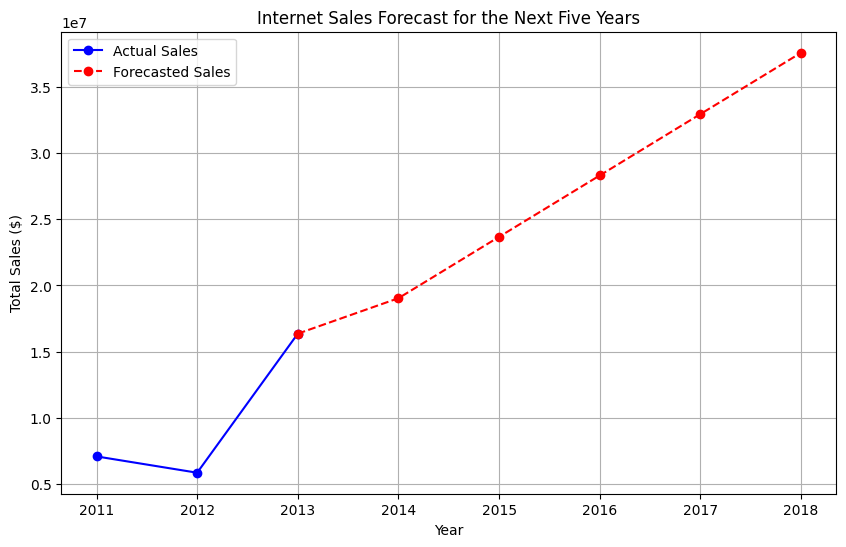

In [3]:
plt.figure(figsize=(10, 6))
#plot actual historical sales
plt.plot(
    years,
    sales,
    marker='o',
    label='Actual Sales',
    color='blue'
)

#plot forecasted sales
plt.plot(
    np.append(years[-1], future_years),
    np.append(sales[-1], forecast_sales),
    marker='o',
    linestyle='--',
    label='Forecasted Sales',
    color='red'
)

#add chart labels
plt.title('Internet Sales Forecast for the Next Five Years')
plt.xlabel('Year')
plt.ylabel('Total Sales ($)')

plt.legend()
plt.grid(True)

plt.show()